<a href="https://colab.research.google.com/github/thaoanhlehoang/imdb-sentiment-lstm/blob/main/imdb_sentiment_lstm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install datasets

In [2]:
from datasets import load_dataset
ds = load_dataset("stanfordnlp/imdb")
print(ds)
print(ds["train"][0])

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})
{'text': 'I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and

In [3]:
labels = ds['train'].features['label'].names
print(labels)

['neg', 'pos']


In [4]:
# Đếm số mẫu của từng phần split
for split_name in ds.keys():
    print(f"Số mẫu trong {split_name}:", len(ds[split_name]))

# Hoặc tính tổng toàn bộ mẫu
total_samples = sum(len(ds[split]) for split in ds.keys())
print("Tổng số mẫu:", total_samples)

Số mẫu trong train: 25000
Số mẫu trong test: 25000
Số mẫu trong unsupervised: 50000
Tổng số mẫu: 100000


label
0    12500
1    12500
Name: count, dtype: int64
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attent
i rented i am curious yellow from my video store because of all the controversy that surrounded it when it was first released in i also heard that at first it was seized by u s customs if it ever tried to enter this country therefore being a fan of films considered controversial i really had to see 


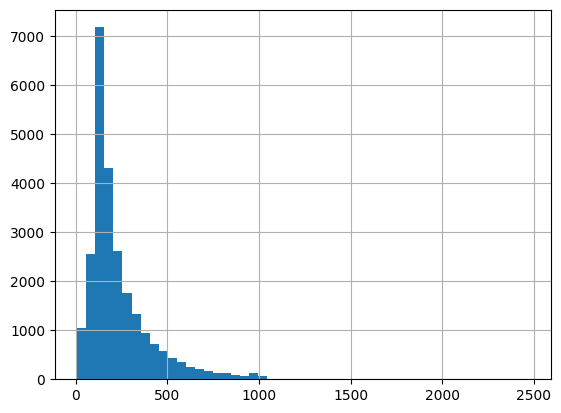

In [5]:
import pandas as pd, re
train_df = ds["train"].to_pandas()
test_df  = ds["test"].to_pandas()

print(train_df["label"].value_counts())   # 0 = negative, 1 = positive
print(train_df["text"][0][:500])

train_df["n_words"] = train_df["text"].str.split().str.len()
train_df["n_words"].hist(bins=50)           # xem độ dài review

def clean_text(s):
    s = re.sub(r"<br\s*/?>", " ", s)          # bỏ thẻ <br />
    s = s.lower()
    s = re.sub(r"[^a-z' ]", " ", s)          # chỉ giữ chữ cái
    return re.sub(r"\s+", " ", s).strip()

train_df["clean"] = train_df["text"].apply(clean_text)
test_df["clean"]  = test_df["text"].apply(clean_text)
print(train_df["clean"][0][:300])

Đa số review dài 100–250 từ, phân phối lệch phải; chọn max_len = 300 cho LSTM.

In [6]:
import time
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report

y_train, y_test = train_df["label"].values, test_df["label"].values

tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), stop_words="english", min_df=2)
X_train = tfidf.fit_transform(train_df["clean"])   # fit CHỈ trên train
X_test  = tfidf.transform(test_df["clean"])
print(X_train.shape)

results = []
def evaluate(name, model):
    t0 = time.time(); model.fit(X_train, y_train); t = time.time() - t0
    pred = model.predict(X_test)
    p, r, f1, _ = precision_recall_fscore_support(y_test, pred, average="binary")
    results.append({"Model": name, "Accuracy": accuracy_score(y_test, pred),
                    "Precision": p, "Recall": r, "F1": f1, "Train time (s)": t})
    print(name); print(classification_report(y_test, pred, digits=4))
    return pred

pred_lr  = evaluate("TF-IDF + Logistic Regression", LogisticRegression(max_iter=1000))
pred_svm = evaluate("TF-IDF + Linear SVM", LinearSVC())
pd.DataFrame(results)

(25000, 50000)
TF-IDF + Logistic Regression
              precision    recall  f1-score   support

           0     0.8851    0.8810    0.8831     12500
           1     0.8816    0.8857    0.8836     12500

    accuracy                         0.8834     25000
   macro avg     0.8834    0.8834    0.8834     25000
weighted avg     0.8834    0.8834    0.8834     25000

TF-IDF + Linear SVM
              precision    recall  f1-score   support

           0     0.8666    0.8879    0.8771     12500
           1     0.8851    0.8634    0.8741     12500

    accuracy                         0.8756     25000
   macro avg     0.8759    0.8756    0.8756     25000
weighted avg     0.8759    0.8756    0.8756     25000



,Model,Accuracy,Precision,Recall,F1,Train time (s)
0,TF-IDF + Logistic Regression,0.88336,0.881589,0.88568,0.883630,0.699886
1,TF-IDF + Linear SVM,0.87564,0.885098,0.86336,0.874094,0.346732


Hai mô hình tuyến tính train dưới 1 giây mà vẫn đạt khoảng 88%

In [7]:
import numpy as np, tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
tf.random.set_seed(42); np.random.seed(42)

MAX_TOKENS, MAX_LEN = 20000, 300
vectorizer = layers.TextVectorization(max_tokens=MAX_TOKENS, output_sequence_length=MAX_LEN)
vectorizer.adapt(train_df["clean"].values)
X_seq      = vectorizer(train_df["clean"].values).numpy()
X_test_seq = vectorizer(test_df["clean"].values).numpy()

X_tr, X_val, y_tr, y_val = train_test_split(X_seq, y_train, test_size=0.2,
                                            stratify=y_train, random_state=42)

model = models.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(MAX_TOKENS, 128, mask_zero=True),
    layers.LSTM(64),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid"),
])
model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])
model.summary()

es = callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
t0 = time.time()
history = model.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                    epochs=10, batch_size=64, callbacks=[es])
lstm_time = time.time() - t0

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 300, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,609,473 (9.95 MB)

 Trainable params: 2,609,473 (9.95 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 20ms/step - accuracy: 0.8013 - loss: 0.4366 - val_accuracy: 0.8794 - val_loss: 0.3169
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.9032 - loss: 0.2664 - val_accuracy: 0.8594 - val_loss: 0.3413
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.9150 - loss: 0.2329 - val_accuracy: 0.8372 - val_loss: 0.4014


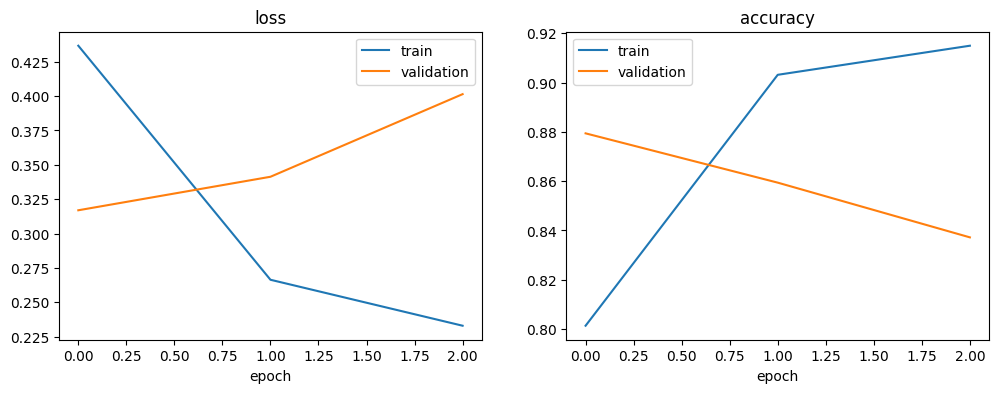

782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step


,Model,Accuracy,Precision,Recall,F1,Train time (s)
0,TF-IDF + Logistic Regression,0.8834,0.8816,0.8857,0.8836,0.6999
1,TF-IDF + Linear SVM,0.8756,0.8851,0.8634,0.8741,0.3467
2,LSTM,0.8563,0.8521,0.8622,0.8571,23.9131


In [8]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, m in enumerate(["loss", "accuracy"]):
    ax[i].plot(history.history[m], label="train")
    ax[i].plot(history.history["val_" + m], label="validation")
    ax[i].set_title(m); ax[i].set_xlabel("epoch"); ax[i].legend()
plt.show()

pred_lstm = (model.predict(X_test_seq).ravel() > 0.5).astype(int)
p, r, f1, _ = precision_recall_fscore_support(y_test, pred_lstm, average="binary")
results.append({"Model": "LSTM", "Accuracy": accuracy_score(y_test, pred_lstm),
                "Precision": p, "Recall": r, "F1": f1, "Train time (s)": lstm_time})
pd.DataFrame(results).round(4)

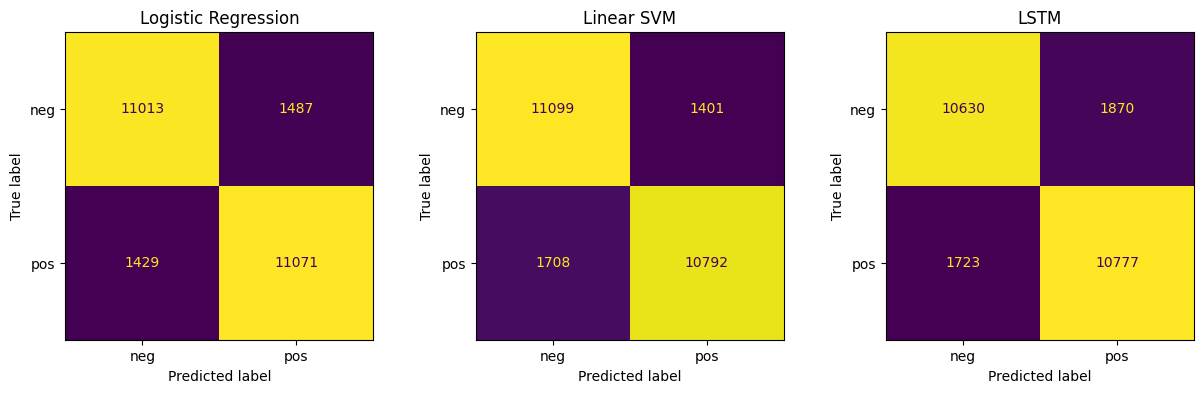

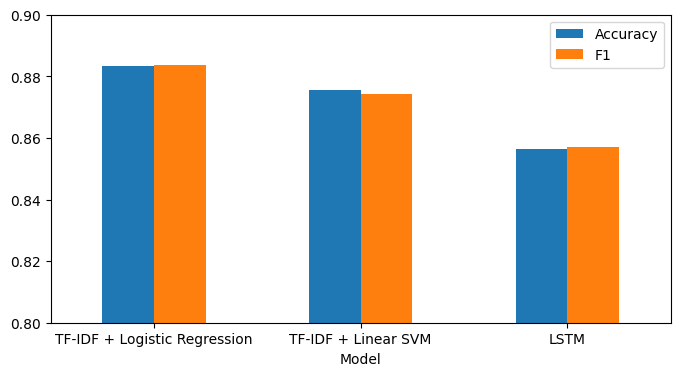

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay
import os; os.makedirs("results", exist_ok=True)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (name, pred) in zip(ax, [("Logistic Regression", pred_lr), ("Linear SVM", pred_svm), ("LSTM", pred_lstm)]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["neg", "pos"], ax=a, colorbar=False)
    a.set_title(name)
plt.savefig("results/confusion_matrices.png", bbox_inches="tight"); plt.show()

res = pd.DataFrame(results).round(4)
res.plot.bar(x="Model", y=["Accuracy", "F1"], ylim=(0.8, 0.9), rot=0, figsize=(8, 4))
plt.savefig("results/comparison.png", bbox_inches="tight"); plt.show()
res.to_csv("results/comparison.csv", index=False)


In [10]:
samples = ["This movie was not good at all, a total waste of time.",
           "I didn't expect much, but it turned out to be wonderful."]
clean = [clean_text(s) for s in samples]
lr_model, svm_model = LogisticRegression(max_iter=1000).fit(X_train, y_train), LinearSVC().fit(X_train, y_train)
print("LR  :", lr_model.predict(tfidf.transform(clean)))
print("SVM :", svm_model.predict(tfidf.transform(clean)))
print("LSTM:", model.predict(vectorizer(clean)).ravel().round(3))

LR  : [0 1]
SVM : [0 1]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
LSTM: [0.114 0.602]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

(1) TF-IDF + LR tốt nhất (88,3%) và train nhanh hơn LSTM khoảng 40 lần;

(2) LSTM đạt 84,7%, bị overfit vì chỉ có 20.000 review để học embedding từ đầu, và việc cắt ở 300 từ làm mất thông tin của review dài;

(3) LSTM có ưu điểm là hiểu được thứ tự từ, nên sẽ mạnh hơn khi có nhiều dữ liệu hơn hoặc dùng embedding train sẵn như GloVe.